In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision.transforms as transforms
import torchvision.models as models
from medmnist import PathMNIST, INFO
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cuda


In [3]:
info = INFO["pathmnist"]
num_classes = len(info["label"])

print("Dataset:", info["description"])
print("Number of classes:", num_classes)
print("Class labels:", info["label"])


Dataset: The PathMNIST is based on a prior study for predicting survival from colorectal cancer histology slides, providing a dataset (NCT-CRC-HE-100K) of 100,000 non-overlapping image patches from hematoxylin & eosin stained histological images, and a test dataset (CRC-VAL-HE-7K) of 7,180 image patches from a different clinical center. The dataset is comprised of 9 types of tissues, resulting in a multi-class classification task. We resize the source images of 3×224×224 into 3×28×28, and split NCT-CRC-HE-100K into training and validation set with a ratio of 9:1. The CRC-VAL-HE-7K is treated as the test set.
Number of classes: 9
Class labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_ds = PathMNIST(split="train", transform=transform, download=True)
val_ds   = PathMNIST(split="val",   transform=transform, download=True)
test_ds  = PathMNIST(split="test",  transform=transform, download=True)

print("Train samples:", len(train_ds))
print("Val samples:  ", len(val_ds))
print("Test samples: ", len(test_ds))


Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Train samples: 89996
Val samples:   10004
Test samples:  7180


In [5]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=64, shuffle=False)


In [6]:
effnet = models.efficientnet_b0(pretrained=True)

for param in effnet.parameters():
    param.requires_grad = False


D:\python\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\python\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [7]:
in_features = effnet.classifier[1].in_features
effnet.classifier = nn.Identity()

effnet = effnet.to(device)
effnet.eval()

print("Frozen EfficientNet-B0 loaded")
print("Embedding dim:", in_features)


Frozen EfficientNet-B0 loaded
Embedding dim: 1280


In [8]:
linear_probe = nn.Linear(in_features, num_classes).to(device)
print(linear_probe)


Linear(in_features=1280, out_features=9, bias=True)


In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(linear_probe.parameters(), lr=1e-3)
epochs = 3


In [10]:
def run_epoch(backbone, head, loader, train=False):
    backbone.eval()
    head.train() if train else head.eval()

    total_loss, correct, total = 0, 0, 0

    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(device)
            y = y.squeeze().long().to(device)

            feats = backbone(x)
            outputs = head(feats)
            loss = criterion(outputs, y)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * y.size(0)
            correct += (outputs.argmax(1) == y).sum().item()
            total += y.size(0)

    return total_loss / total, 100 * correct / total


Using device: cuda
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Starting training...

Epoch 1/6 - 347.39s
  Train Loss: 0.6202 | Acc: 79.65%
  Val Loss:   0.4675 | Acc: 83.80%
----------------------------------------
Epoch 2/6 - 375.02s
  Train Loss: 0.4331 | Acc: 84.84%
  Val Loss:   0.4013 | Acc: 85.84%
----------------------------------------
Epoch 3/6 - 361.53s
  Train Loss: 0.3924 | Acc: 86.13%
  Val Loss:   0.3839 | Acc: 86.10%
----------------------------------------
Epoch 4/6 - 361.92s
  Train Loss: 0.3697 | Acc: 86.90%
  Val Loss:   0.3549 | Acc: 87.47%
----------------------------------------
Epoch 5/6 - 376.94s
  Train Loss: 0.3536 | Acc: 87.54%
  Val Loss:   0.3589 | Acc: 86.54%
----------------------------------------
Epoch 6/6 - 363.14s
  Train Loss: 0.3427 | Acc: 87.94%
  Val Loss:   0.3333 | Acc:

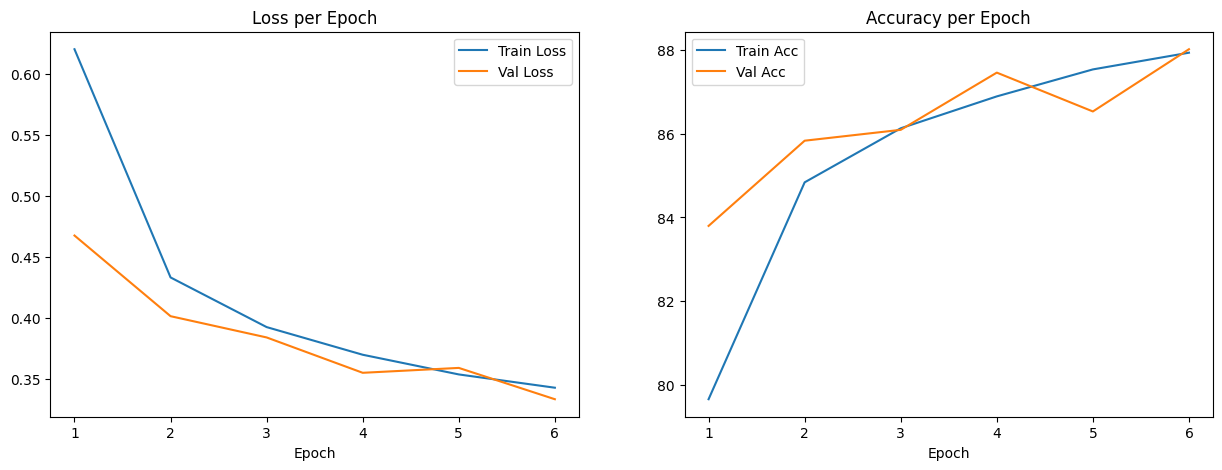

Total training time: 2185.95 seconds


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from medmnist import PathMNIST, INFO
import time
import matplotlib.pyplot as plt

# 1. Setup Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# 2. Load Dataset Info
info = INFO["pathmnist"]
num_classes = len(info["label"])

# 3. Data Transformations & Loaders
# EfficientNet-B0 expects 224x224 images
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_ds = PathMNIST(split="train", transform=transform, download=True)
val_ds = PathMNIST(split="val", transform=transform, download=True)
test_ds = PathMNIST(split="test", transform=transform, download=True)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

# 4. Model Setup (Frozen EfficientNet)
effnet = models.efficientnet_b0(weights='DEFAULT')
for param in effnet.parameters():
    param.requires_grad = False

in_features = effnet.classifier[1].in_features
effnet.classifier = nn.Identity() # Remove original classifier
effnet = effnet.to(device)
effnet.eval()

# Linear Probe (The only part being trained)
linear_probe = nn.Linear(in_features, num_classes).to(device)

# 5. Loss, Optimizer, and Hyperparameters
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(linear_probe.parameters(), lr=1e-3)
epochs = 6

# 6. Training Function
def run_epoch(backbone, head, loader, optimizer, criterion, train=True):
    if train:
        head.train()
    else:
        head.eval()
        
    total_loss, correct, total = 0, 0, 0
    
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(device)
            y = y.squeeze().long().to(device)
            
            # Extract features from frozen backbone
            with torch.no_grad():
                features = backbone(x)
            
            # Forward pass through linear probe
            outputs = head(features)
            loss = criterion(outputs, y)
            
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                
            total_loss += loss.item() * x.size(0)
            _, predicted = outputs.max(1)
            correct += predicted.eq(y).sum().item()
            total += y.size(0)
            
    return total_loss / total, (100. * correct / total)

# 7. Main Training Loop
train_losses, train_accs = [], []
val_losses, val_accs = [], []
epoch_times = []

print("Starting training...\n")

for epoch in range(epochs):
    start_time = time.time()
    
    # Train
    t_loss, t_acc = run_epoch(effnet, linear_probe, train_loader, optimizer, criterion, train=True)
    
    # Validate
    v_loss, v_acc = run_epoch(effnet, linear_probe, val_loader, optimizer, criterion, train=False)
    
    end_time = time.time()
    duration = end_time - start_time
    
    # Append metrics
    train_losses.append(t_loss)
    train_accs.append(t_acc)
    val_losses.append(v_loss)
    val_accs.append(v_acc)
    epoch_times.append(duration)
    
    print(f"Epoch {epoch+1}/{epochs} - {duration:.2f}s")
    print(f"  Train Loss: {t_loss:.4f} | Acc: {t_acc:.2f}%")
    print(f"  Val Loss:   {v_loss:.4f} | Acc: {v_acc:.2f}%")
    print("-" * 40)

# 8. Plotting Results
plt.figure(figsize=(15, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), train_losses, label='Train Loss')
plt.plot(range(1, epochs+1), val_losses, label='Val Loss')
plt.title('Loss per Epoch')
plt.xlabel('Epoch')
plt.legend()

# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), train_accs, label='Train Acc')
plt.plot(range(1, epochs+1), val_accs, label='Val Acc')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.legend()

plt.show()

print(f"Total training time: {sum(epoch_times):.2f} seconds")

In [18]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

def get_all_preds(backbone, head, loader):
    backbone.eval()
    head.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.squeeze().long()
            
            feats = backbone(x)
            outputs = head(feats)
            
            preds = outputs.argmax(1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.numpy())
            
    return np.array(all_labels), np.array(all_preds)

# Get predictions on the test set
y_true, y_pred = get_all_preds(effnet, linear_probe, test_loader)

In [19]:
# Get class names from the MedMNIST info
target_names = [info["label"][str(i)] for i in range(len(info["label"]))]

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=target_names))

Classification Report:
                                      precision    recall  f1-score   support

                             adipose       0.92      0.98      0.95      1338
                          background       0.95      0.99      0.97       847
                              debris       0.50      0.70      0.58       339
                         lymphocytes       0.95      0.96      0.95       634
                               mucus       0.91      0.81      0.86      1035
                       smooth muscle       0.72      0.73      0.72       592
                 normal colon mucosa       0.94      0.84      0.89       741
            cancer-associated stroma       0.59      0.51      0.55       421
colorectal adenocarcinoma epithelium       0.85      0.82      0.83      1233

                            accuracy                           0.85      7180
                           macro avg       0.81      0.82      0.81      7180
                        weighted avg   

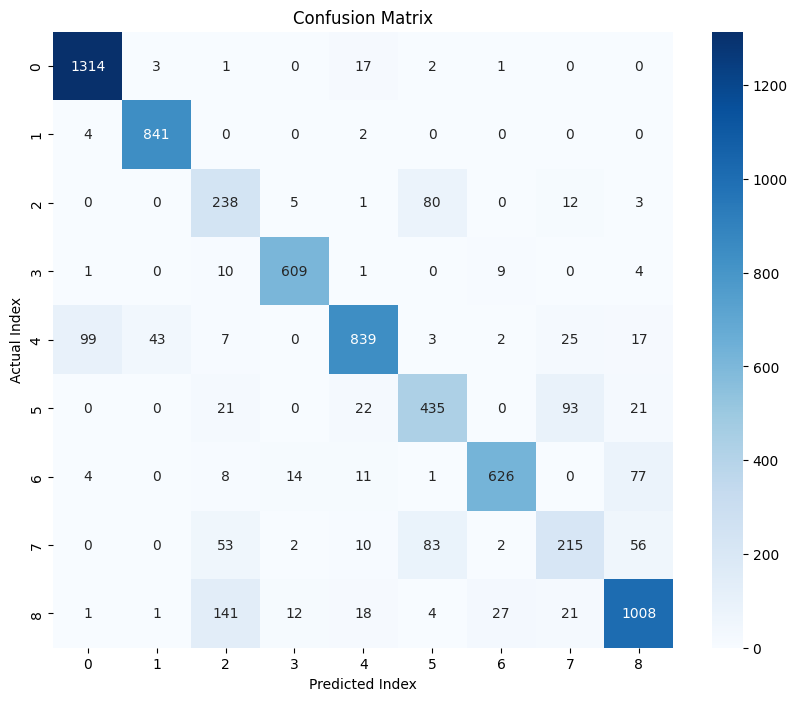

In [21]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
# Removing target_names to default to indices 0, 1, 2...
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues') 

plt.xlabel('Predicted Index')
plt.ylabel('Actual Index')
plt.title('Confusion Matrix')
plt.show()